In [1]:
import os, importlib, sys, time

In [2]:
import numpy as np
import scipy.sparse as sparse
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from tqdm import tqdm

In [3]:
import KECENI

# load data

In [4]:
data_dir = 'data'

In [5]:
i_sim = 1

In [6]:
data_network = pd.read_feather('%s/network.feather'%(data_dir))
data_latent = pd.read_feather('%s/latent.feather'%data_dir)
data_feature = pd.read_feather('%s/feature_%.3d.feather'%(data_dir, i_sim))

In [7]:
data_network

,row,col
0,1,5
1,1,17
2,2,3
3,2,9
4,3,2
...,...,...
3621,999,837
3622,999,930
3623,999,989
3624,999,993


In [8]:
data_feature

,X1,X2,X3,p,T,m,Y
0,-0.447027,-0.705126,0.266350,0.391050,1,0.688503,0.692363
1,1.219795,0.637921,1.272363,0.827075,0,-7.103306,-6.488132
2,0.790879,0.837265,0.608502,0.753678,1,-3.974438,-2.137433
3,-1.079978,-1.804343,-2.574626,0.061256,0,8.294056,9.525241
4,-0.437606,0.003347,0.423150,0.498611,0,-2.155245,-3.193287
...,...,...,...,...,...,...,...
995,0.566763,-0.501376,0.086047,0.518920,0,3.092675,4.496140
996,-1.454455,1.275978,1.752639,0.687204,1,-2.954723,-5.044276
997,-0.740551,-0.501887,1.173634,0.491400,0,-3.518165,-3.671195
998,0.143803,1.283810,0.483779,0.722259,0,-3.085424,-3.713241


In [9]:
n_node = len(data_latent); n_node

1000

In [10]:
len(data_network)

3626

In [11]:
Adj = sparse.csr_matrix((
    np.full(len(data_network), True), 
    (np.array(data_network.row)-1, np.array(data_network.col)-1)
), shape=(n_node,n_node)).toarray()

In [12]:
G = KECENI.Graph(Adj)

In [13]:
Ys = data_feature.iloc[:,6].values
Ts = data_feature.iloc[:,4].values
Xs = data_feature.iloc[:,0:3].values

In [14]:
data = KECENI.Data(Ys, Ts, Xs, G)

# hyperparameters

In [15]:
from hyperparams import avg_mu, avg_pi, avg, wavg_mu, wavg_pi, wavg, GW, L1

In [16]:
alpha_T = 1/np.std(Ts)
alpha_X = 1

In [17]:
GW_data = GW(alpha_T, alpha_X)
L1_wavg = L1(wavg_mu, wavg_pi, wavg)
L1_avg = L1(avg_mu, avg_pi, avg)

# counterfactual of interest

In [18]:
i0 = 0

In [19]:
T0s_0 = np.full(n_node, 0)
T0s_1 = np.full(n_node, 1)

In [20]:
T0s_0[G.N1(i0)], T0s_1[G.N1(i0)]

(array([0, 0, 0]), array([1, 1, 1]))

In [21]:
i0s = np.array([i0])
T0s = np.array([T0s_0, T0s_1])

# groundtruth

In [22]:
from KECENI.RegressionModel import FittedRegressionModel
from KECENI.PropensityModel import FittedPropensityModel
from KECENI.CovariateModel import FittedCovariateModel

In [23]:
from true_model import mu, pi, rX

In [24]:
true_model = KECENI.Model(
    FittedRegressionModel(mu),
    FittedPropensityModel(pi),
    FittedCovariateModel(rX),
    L1_wavg.delta
)

In [25]:
true_fit = true_model.fit(data, n_process=1)

In [26]:
result_true = true_fit.G_estimate(i0s, T0s, n_X=10000)

In [27]:
YTR_0, YTR_1 = result_true.reshape([2,-1])
YTR_d = YTR_1 - YTR_0

In [28]:
YTR_0, YTR_1, YTR_d

(array([-1.9891602]), array([1.94485051]), array([3.93401071]))

In [29]:
G.sub(G.N1(i0)).Adj

array([[False,  True,  True],
       [ True, False, False],
       [ True, False, False]])

# estimation

In [30]:
from KECENI.RegressionModel import LinearRegressionModel
from KECENI.PropensityModel import LogisticIIDPropensityModel
from KECENI.CovariateModel import IIDCovariateModel

In [31]:
model_wavg = KECENI.Model(
    LinearRegressionModel(avg_mu),
    LogisticIIDPropensityModel(avg_pi),
    IIDCovariateModel(bal=False),
    L1_wavg.delta,
)

In [32]:
model_avg = KECENI.Model(
    LinearRegressionModel(avg_mu),
    LogisticIIDPropensityModel(avg_pi),
    IIDCovariateModel(bal=False),
    L1_avg.delta,
)

In [33]:
model_GW = KECENI.Model(
    LinearRegressionModel(avg_mu),
    LogisticIIDPropensityModel(avg_pi),
    IIDCovariateModel(bal=False),
    GW_data.delta,
)

In [34]:
fit_wavg = model_wavg.fit(data, tqdm=tqdm)

fit: 100%|██████████| 1000/1000 [00:05<00:00, 171.04it/s]


In [35]:
fit_avg = model_avg.fit(data, tqdm=tqdm,
                      mus=fit_wavg.mus, pis=fit_wavg.pis, ms=fit_wavg.ms, vps=fit_wavg.vps)

In [36]:
fit_GW = model_GW.fit(data, tqdm=tqdm,
                      mus=fit_wavg.mus, pis=fit_wavg.pis, ms=fit_wavg.ms, vps=fit_wavg.vps)

## - cross-validation

In [37]:
lamdas = np.linspace(0, 20, 21)[1:]

In [38]:
cv_wavg = fit_wavg.cv(
    tqdm=tqdm
)

cv: 100%|██████████| 1000/1000 [00:13<00:00, 76.23it/s]


In [39]:
cv_avg = fit_avg.cv(
    tqdm=tqdm
)

cv: 100%|██████████| 1000/1000 [00:12<00:00, 79.78it/s]


In [40]:
cv_GW = fit_GW.cv(
    tqdm=tqdm
)

cv: 100%|██████████| 1000/1000 [00:34<00:00, 29.37it/s]


In [41]:
i=4

In [42]:
GW_data.delta(T0s_0[G.N1(i0)], G.sub(G.N2(i0)), Ts[G.N1(i)], G.sub(G.N2(i)))

0.9930822235022905

In [43]:
L1_wavg.delta(T0s_0[G.N1(i0)], G.sub(G.N2(i0)), Ts[G.N1(i)], G.sub(G.N2(i)))

1.3333333333333335

In [44]:
L1_avg.delta(T0s_0[G.N1(i0)], G.sub(G.N2(i0)), Ts[G.N1(i)], G.sub(G.N2(i)))

0.8333333333333334

In [45]:
def exponential_kernel(x):
    return np.exp(-np.abs(x))

In [46]:
xs_wavg, xhs_wavg = cv_wavg.xs_xhs(lamdas, kernel=exponential_kernel)

In [47]:
xs_avg, xhs_avg = cv_avg.xs_xhs(lamdas, kernel=exponential_kernel)

In [48]:
xs_GW, xhs_GW = cv_GW.xs_xhs(lamdas, kernel=exponential_kernel)

Text(0, 0.5, 'MSE')

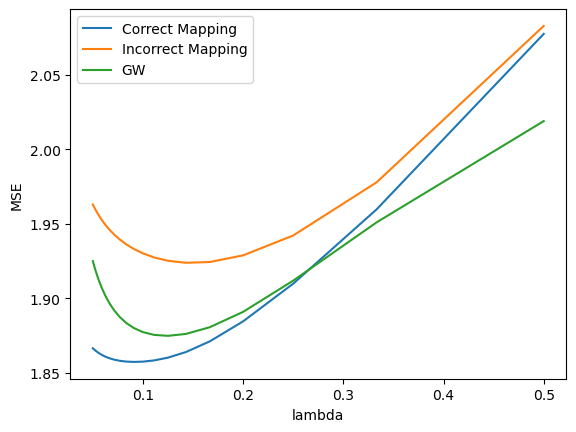

In [50]:
plt.plot(1/lamdas[1:], np.mean((xs_avg-xhs_avg)**2, -1)[1:])
plt.plot(1/lamdas[1:], np.mean((xs_wavg-xhs_wavg)**2, -1)[1:])
plt.plot(1/lamdas[1:], np.mean((xs_GW-xhs_GW)**2, -1)[1:])
plt.legend(['Correct Mapping', 'Incorrect Mapping', 'GW'])
plt.xlabel('lambda')
plt.ylabel('MSE')

blue: correct summary statistics (T_i, \sum_j T_j * d_ij / d_i)
orange: incorrect summary statistics (T_i, \sum_j T_j / d_i)
green: nonparametric dissimilarity metric (Gromov-Wasserstein)

In [50]:
np.min(np.mean((xs_wavg-xhs_wavg)**2, -1)), np.min(np.mean((xs_avg-xhs_avg)**2, -1)), np.min(np.mean((xs_GW-xhs_GW)**2, -1))

(1.9183163311854032, 1.854647810337885, 1.8719359815202632)

In [51]:
id_avg = np.argmin(np.mean((xs_avg-xhs_avg)**2, -1))
id_wavg = np.argmin(np.mean((xs_wavg-xhs_wavg)**2, -1))
id_GW = np.argmin(np.mean((xs_GW-xhs_GW)**2, -1))

In [52]:
# id_cv = 10

In [53]:
lamdas[id_avg], lamdas[id_wavg], lamdas[id_GW]

(11.0, 7.0, 8.0)

## - G estimate

In [54]:
result_G = fit_avg.G_estimate(i0s, T0s, n_X=1000)

In [55]:
YG_0, YG_1 = np.moveaxis(result_G, -1, 0)
YG_d = YG_1 - YG_0

In [56]:
YG_0, YG_1, YG_d

(-1.863855950274818, 2.340183500634451, 4.204039450909269)

## - KECENI

In [57]:
result_avg = fit_avg.kernel_AIPW(
    i0s, T0s, tqdm=tqdm
)

AIPW: 100%|██████████| 1000/1000 [00:06<00:00, 146.84it/s]


In [58]:
result_wavg = fit_wavg.kernel_AIPW(
    i0s, T0s, tqdm=tqdm
)

AIPW: 100%|██████████| 1000/1000 [00:06<00:00, 153.65it/s]


In [59]:
result_GW = fit_GW.kernel_AIPW(
    i0s, T0s, tqdm=tqdm
)

AIPW: 100%|██████████| 1000/1000 [00:06<00:00, 162.72it/s]


In [60]:
# avg
YDR_0_avg, YDR_1_avg = np.moveaxis(result_avg.est(lamdas, exponential_kernel), -1, 0)
YDR_d_avg = YDR_1_avg - YDR_0_avg
YDR_0_avg[id_avg], YDR_1_avg[id_avg], YDR_d_avg[id_avg]

(-1.710738424079605, 2.1718570388258525, 3.8825954629054573)

In [61]:
# wavg
YDR_0_wavg, YDR_1_wavg = np.moveaxis(result_wavg.est(lamdas, exponential_kernel), -1, 0)
YDR_d_wavg = YDR_1_wavg - YDR_0_wavg
YDR_0_wavg[id_wavg], YDR_1_wavg[id_wavg], YDR_d_wavg[id_wavg]

(-1.4770964079300786, 1.8988704665511003, 3.375966874481179)

In [62]:
# GW
YDR_0_GW, YDR_1_GW = np.moveaxis(result_GW.est(lamdas, exponential_kernel), -1, 0)
YDR_d_GW = YDR_1_GW - YDR_0_GW
YDR_0_GW[id_GW], YDR_1_GW[id_GW], YDR_d_GW[id_GW]

(-1.6140016882959316, 2.078567869686094, 3.6925695579820257)